In [2]:
#env_STAligner
import torch, os
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version PyTorch expects:", torch.version.cuda)
print("LD_LIBRARY_PATH:", os.environ.get("LD_LIBRARY_PATH"))

PyTorch version: 1.9.1+cu102
CUDA available: True
CUDA version PyTorch expects: 10.2
LD_LIBRARY_PATH: None


/home/adyprat/anaconda3/envs/env_STAligner/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import anndata as ad
import scanpy as sc
import pandas as pd
import numpy as np
import scipy.sparse as sp
import scipy.linalg
import STAligner
import torch
used_device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [4]:
import scanpy as sc 

#run using env_stalign from here
import pandas as pd
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad

refExpression = pd.read_csv('refSubAD_expression.csv', index_col=0)
queryExpression = pd.read_csv('querySubAD_expression.csv', index_col=0)
refObs = pd.read_csv('refSubAD_obs.csv', index_col=0)
queryObs = pd.read_csv('querySubAD_obs.csv', index_col=0)

refAD = ad.AnnData(X=refExpression.values, obs=refObs)
queryAD = ad.AnnData(X=queryExpression.values, obs=queryObs)

refAD.var_names = refExpression.columns
queryAD.var_names = queryExpression.columns

# sc.pp.normalize_total(refAD, target_sum=1e2)
# sc.pp.normalize_total(queryAD, target_sum=1e2)
# sc.pp.log1p(refAD)
# sc.pp.log1p(queryAD)
queryAD.obs['spatial_domain_original'] = queryAD.obs['spatial_domain'].copy()
refAD.obs['spatial_domain_original'] = refAD.obs['spatial_domain'].copy()

queryAD.obs['slice_name'] = 'protein'
refAD.obs['slice_name'] = 'rna'

/home/adyprat/anaconda3/envs/env_STAligner/lib/python3.8/site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/adyprat/anaconda3/envs/env_STAligner/lib/python3.8/site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [5]:
queryAD

AnnData object with n_obs × n_vars = 4671 × 16
    obs: 'Image', 'Object ID', 'Object type', 'Name', 'Classification', 'Parent', 'ROI', 'Centroid X µm', 'Centroid Y µm', 'Nucleus: Area', 'Nucleus: Perimeter', 'Nucleus: Circularity', 'Nucleus: Max caliper', 'Nucleus: Min caliper', 'Nucleus: Eccentricity', 'Nucleus: DAPI sum', 'Nucleus: DAPI std dev', 'Nucleus: DAPI max', 'Nucleus: DAPI min', 'Nucleus: DAPI range', 'Nucleus: CD8 sum', 'Nucleus: CD8 std dev', 'Nucleus: CD8 max', 'Nucleus: CD8 min', 'Nucleus: CD8 range', 'Nucleus: CD20 sum', 'Nucleus: CD20 std dev', 'Nucleus: CD20 max', 'Nucleus: CD20 min', 'Nucleus: CD20 range', 'Nucleus: CD4 sum', 'Nucleus: CD4 std dev', 'Nucleus: CD4 max', 'Nucleus: CD4 min', 'Nucleus: CD4 range', 'Nucleus: GZMB sum', 'Nucleus: GZMB std dev', 'Nucleus: GZMB max', 'Nucleus: GZMB min', 'Nucleus: GZMB range', 'Nucleus: FOXP3 sum', 'Nucleus: FOXP3 std dev', 'Nucleus: FOXP3 max', 'Nucleus: FOXP3 min', 'Nucleus: FOXP3 range', 'Nucleus: Ki67 sum', 'Nucleus: Ki

In [6]:

import numpy as np

# If queryAD.X is a sparse matrix, convert to dense for transformation
if hasattr(queryAD.X, "toarray"):
    X_dense = queryAD.X.toarray()
else:
    X_dense = queryAD.X

# Invert log1p transformation (if that was the scaling used)
X_counts = np.expm1(X_dense)
X_counts[X_counts < 0] = 0  # Ensure no negative counts

queryAD.X = X_counts


In [7]:
refAD

AnnData object with n_obs × n_vars = 3608 × 16
    obs: 'fov', 'volume', 'center_x', 'center_y', 'min_x', 'min_y', 'max_x', 'max_y', 'anisotropy', 'transcript_count', 'perimeter_area_ratio', 'solidity', 'Anti-Chicken_raw', 'Anti-Chicken_high_pass', 'PolyT_raw', 'PolyT_high_pass', 'Cellbound2_raw', 'Cellbound2_high_pass', 'Anti-Human_raw', 'Anti-Human_high_pass', 'DAPI_raw', 'DAPI_high_pass', 'Anti-Rat_raw', 'Anti-Rat_high_pass', 'Anti-Mouse_raw', 'Anti-Mouse_high_pass', 'Cellbound3_raw', 'Cellbound3_high_pass', 'Cellbound1_raw', 'Cellbound1_high_pass', 'Anti-Goat_raw', 'Anti-Goat_high_pass', 'Anti-Rabbit_raw', 'Anti-Rabbit_high_pass', 'DAPI_raw_log', 'n_counts', 'transformed_x', 'transformed_y', 'in_ROI', 'pred_cell_type', 'New_X', 'New_Y', 'CellType', 'image_id', 'spatial_domain', 'spatial_domain_original', 'slice_name'

In [8]:
Batch_list = []
adj_list = []
for adata in [refAD, queryAD]:
    adata.obsm['X_spatial'] = np.array([adata.obs['New_X'].values, adata.obs['New_Y'].values]).T
    adata.obsm['spatial'] = adata.obsm['X_spatial'].copy()
    # Constructing the spatial network
    adata.X = sp.csr_matrix(adata.X)
    if 'Object ID' in adata.obs.columns:
        adata.obs['cellID'] = adata.obs['Object ID'].values
    else:
        adata.obs['cellID'] = adata.obs.index.values
    STAligner.Cal_Spatial_Net(adata, rad_cutoff=250) # the spatial network are saved in adata.un
    sc.pp.normalize_total(adata, target_sum=1e2)
    sc.pp.log1p(adata)
    adj_list.append(adata.uns['adj'])
    Batch_list.append(adata)

------Calculating spatial graph...


/mnt/e/git-workspace/STAligner/STAligner/ST_utils.py:83: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Spatial_Net['Cell1'] = Spatial_Net['Cell1'].map(id_cell_trans)
/mnt/e/git-workspace/STAligner/STAligner/ST_utils.py:84: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Spatial_Net['Cell2'] = Spatial_Net['Cell2'].map(id_cell_trans)
/home/adyprat/anaconda3/envs/env_STAligner/lib/python3.8/site-packages/scanpy/preprocessing/_normalization.py:197: UserWarning: Some cells have zero counts
  warn(UserWarning('Some

The graph contains 172846 edges, 3608 cells.
47.9063 neighbors per cell on average.
------Calculating spatial graph...
The graph contains 228300 edges, 4671 cells.
48.8760 neighbors per cell on average.


/mnt/e/git-workspace/STAligner/STAligner/ST_utils.py:83: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Spatial_Net['Cell1'] = Spatial_Net['Cell1'].map(id_cell_trans)
/mnt/e/git-workspace/STAligner/STAligner/ST_utils.py:84: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  Spatial_Net['Cell2'] = Spatial_Net['Cell2'].map(id_cell_trans)
/home/adyprat/anaconda3/envs/env_STAligner/lib/python3.8/site-packages/scanpy/preprocessing/_normalization.py:197: UserWarning: Some cells have zero counts
  warn(UserWarning('Some

In [9]:
section_ids = ['rna','protein']

In [10]:
Batch_list[1].obs

,Image,Object ID,Object type,Name,Classification,Parent,ROI,Centroid X µm,Centroid Y µm,Nucleus: Area,...,leiden,cell_type,New_X,New_Y,CellType,image_id,spatial_domain,spatial_domain_original,slice_name,cellID
32730,pcf_tongue_roi.ome.tif,6c8df374-8566-4a60-b133-eab85bba713d,Cell,NaN,NaN,Annotation,Polygon,4847.1,6513.5,11.8274,...,4,Myeloid cells,1624.137251,0.000000,Myeloid cells,query,3,3,protein,6c8df374-8566-4a60-b133-eab85bba713d
32737,pcf_tongue_roi.ome.tif,a2b8665d-1a3b-41c0-b377-cc7f0bc63f8d,Cell,NaN,NaN,Annotation,Polygon,4983.3,6516.5,23.3977,...,11,Fibroblasts,1892.723329,5.915993,Fibroblasts,query,3,3,protein,a2b8665d-1a3b-41c0-b377-cc7f0bc63f8d
32740,pcf_tongue_roi.ome.tif,0f4d11bf-16da-4ee0-8bea-a526858d607e,Cell,NaN,NaN,Annotation,Polygon,4827.9,6521.1,22.8835,...,4,Myeloid cells,1586.274896,14.987182,Myeloid cells,query,0,0,protein,0f4d11bf-16da-4ee0-8bea-a526858d607e
32741,pcf_tongue_roi.ome.tif,8a6f6e48-4604-4dae-8e92-47f2ed17b539,Cell,NaN,NaN,Annotation,Polygon,4932.7,6520.4,26.9974,...,4,Myeloid cells,1792.940248,13.606784,Myeloid cells,query,2,2,protein,8a6f6e48-4604-4dae-8e92-47f2ed17b539
32745,pcf_tongue_roi.ome.tif,e390053d-e183-4619-9404-8cd19b907c0d,Cell,NaN,NaN,Annotation,Polygon,4979.3,6526.6,24.4262,...,0,Fibroblasts,1884.835338,25.833169,Fibroblasts,query,3,3,protein,e390053d-e183-4619-9404-8cd19b907c0d
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51378,pcf_tongue_roi.ome.tif,7d23b82f-f95f-4b06-b9d6-b46d0b1cc7c1,Cell,NaN,NaN,Annotation,Polygon,5059.2,8174.5,89.7341,...,6,Epithelial cells,2042.397949,3275.488069,Epithelial cells,query,1,1,protein,7d23b82f-f95f-4b06-b9d6-b46d0b1cc7c1
51379,pcf_tongue_roi.ome.tif,64655e44-732c-4828-a8b7-a9e5060beacf,Cell,NaN,NaN,Annotation,Polygon,5218.1,8176.2,30.3399,...,6,Epithelial cells,2355.748373,3278.840465,Epithelial cells,query,1,1,protein,64655e44-732c-4828-a8b7-a9e5060beacf
51380,pcf_tongue_roi.ome.tif,b2ef3830-7b03-4594-8554-560c195f0285,Cell,NaN,NaN,Annotation,Polygon,5116.0,8182.3,43.7100,...,6,Epithelial cells,2154.407415,3290.869651,Epithelial cells,query,1,1,protein,b2ef3830-7b03-4594-8554-560c195f0285
51381,pcf_tongue_roi.ome.tif,224679f7-efcd-497d-8fcb-202138f053d3,Cell,NaN,NaN,Annotation,Polygon,5161.8,8197.7,38.0534,...,6,Epithelial cells,2244.724906,3321.238415,Epithelial cells,query,1,1,protein,224679f7-efcd-497d-8fcb-202138f053d3


In [11]:
adata_concat = ad.concat(Batch_list, label="slice_name", keys=section_ids)
adata_concat.obs['Ground Truth'] = adata_concat.obs['CellType'].astype('category')
adata_concat.obs["batch_name"] = adata_concat.obs["slice_name"].astype('category')
print('adata_concat.shape: ', adata_concat.shape)


adata_concat.shape:  (8279, 16)


In [12]:
adata_concat.obs

,transformed_x,transformed_y,in_ROI,New_X,New_Y,CellType,image_id,spatial_domain,spatial_domain_original,slice_name,cellID,Ground Truth,batch_name
3443715200455100055,10954.380002,13944.383429,True,3020.047524,1099.776842,Epithelial cells,ref,1,1,rna,3443715200455100055,Epithelial cells,rna
3443715200455100057,10946.573801,13890.089022,True,3012.241322,1045.482436,Epithelial cells,ref,1,1,rna,3443715200455100057,Epithelial cells,rna
3443715200455100058,10945.461033,13911.796937,True,3011.128555,1067.190351,Epithelial cells,ref,1,1,rna,3443715200455100058,Epithelial cells,rna
3443715200455100060,10943.683312,13863.000800,True,3009.350833,1018.394213,Epithelial cells,ref,1,1,rna,3443715200455100060,Epithelial cells,rna
3443715200456100090,11010.086369,13640.624477,True,3075.753890,796.017891,Epithelial cells,ref,1,1,rna,3443715200456100090,Epithelial cells,rna
...,...,...,...,...,...,...,...,...,...,...,...,...,...
51378,9976.730428,16120.094656,True,2042.397949,3275.488069,Epithelial cells,query,1,1,protein,7d23b82f-f95f-4b06-b9d6-b46d0b1cc7c1,Epithelial cells,protein
51379,10290.080852,16123.447052,True,2355.748373,3278.840465,Epithelial cells,query,1,1,protein,64655e44-732c-4828-a8b7-a9e5060beacf,Epithelial cells,protein
51380,10088.739894,16135.476237,True,2154.407415,3290.869651,Epithelial cells,query,1,1,protein,b2ef3830-7b03-4594-8554-560c195f0285,Epithelial cells,protein
51381,10179.057385,16165.845001,True,2244.724906,3321.238415,Epithelial cells,query,1,1,protein,224679f7-efcd-497d-8fcb-202138f053d3,Epithelial cells,protein


In [13]:
adj_concat = np.asarray(adj_list[0].todense())
for batch_id in range(1,len(section_ids)):
    adj_concat = scipy.linalg.block_diag(adj_concat, np.asarray(adj_list[batch_id].todense()))
adata_concat.uns['edgeList'] = np.nonzero(adj_concat)

In [14]:
%%time
adata_concat = STAligner.train_STAligner(adata_concat, verbose=True, knn_neigh = 50, device=used_device)

STAligner(
  (conv1): GATConv(16, 512, heads=1)
  (conv2): GATConv(512, 30, heads=1)
  (conv3): GATConv(30, 512, heads=1)
  (conv4): GATConv(512, 16, heads=1)
)
Pretrain with STAGATE...


100%|██████████| 500/500 [00:24<00:00, 20.30it/s]


Train with STAligner...


  0%|          | 0/500 [00:00<?, ?it/s]

Update spot triplets at epoch 500


 20%|█▉        | 99/500 [00:05<00:19, 20.28it/s]

... (5 outputs left out)

 80%|███████▉  | 399/500 [00:21<00:05, 19.20it/s]

Update spot triplets at epoch 900


100%|██████████| 500/500 [00:27<00:00, 18.37it/s]

CPU times: user 56.6 s, sys: 2.39 s, total: 59 s
Wall time: 55.6 s


In [15]:
sc.pp.neighbors(adata_concat, use_rep='STAligner', random_state=666)
sc.tl.louvain(adata_concat, random_state=666, key_added="louvain", resolution=0.2)
sc.tl.umap(adata_concat)


/home/adyprat/anaconda3/envs/env_STAligner/lib/python3.8/site-packages/umap/distances.py:1063: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/adyprat/anaconda3/envs/env_STAligner/lib/python3.8/site-packages/umap/distances.py:1071: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/adyprat/anaconda3/envs/env_STAligner/lib/python3.8

In [16]:
adata_concat.obs.batch_name

3443715200455100055        rna
3443715200455100057        rna
3443715200455100058        rna
3443715200455100060        rna
3443715200456100090        rna
                        ...   
51378                  protein
51379                  protein
51380                  protein
51381                  protein
51383                  protein
Name: batch_name, Length: 8279, dtype: category
Categories (2, object): ['rna', 'protein']

/home/adyprat/anaconda3/envs/env_STAligner/lib/python3.8/site-packages/anndata/_core/anndata.py:1230: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/adyprat/anaconda3/envs/env_STAligner/lib/python3.8/site-packages/anndata/_core/anndata.py:1230: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


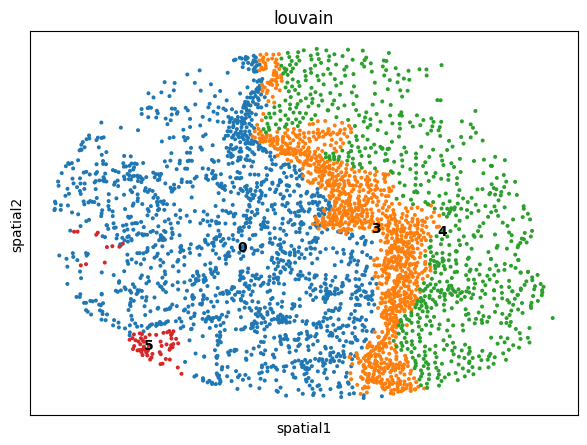

/home/adyprat/anaconda3/envs/env_STAligner/lib/python3.8/site-packages/anndata/_core/anndata.py:1230: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/adyprat/anaconda3/envs/env_STAligner/lib/python3.8/site-packages/anndata/_core/anndata.py:1230: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


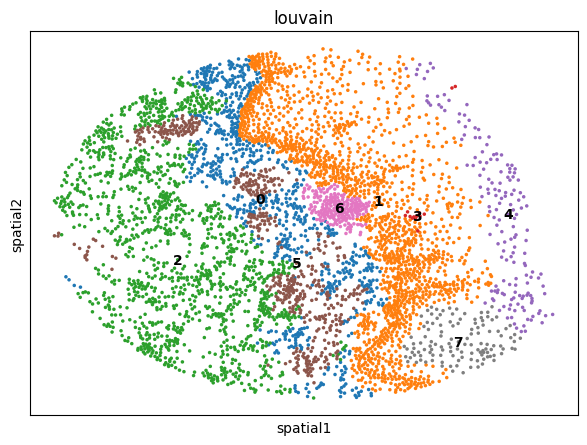

In [17]:
sc.pl.scatter(adata_concat[adata_concat.obs['batch_name']=='rna'], color='louvain', legend_loc='on data', basis='spatial')
sc.pl.scatter(adata_concat[adata_concat.obs['batch_name']=='protein'], color='louvain', legend_loc='on data', basis='spatial')


In [18]:
adata_concat

AnnData object with n_obs × n_vars = 8279 × 16
    obs: 'transformed_x', 'transformed_y', 'in_ROI', 'New_X', 'New_Y', 'CellType', 'image_id', 'spatial_domain', 'spatial_domain_original', 'slice_name', 'cellID', 'Ground Truth', 'batch_name', 'louvain'
    uns: 'edgeList', 'neighbors', 'louvain', 'umap'
    obsm: 'X_spatial', 'spatial', 'STAGATE', 'STAligner', 'X_umap'
    obsp: 'distances', 'connectivities'

In [49]:
adata_target = adata_concat[adata_concat.obs['batch_name']=='protein'].copy()
adata_ref = adata_concat[adata_concat.obs['batch_name']=='rna'].copy()
# Find common domains (louvain clusters) between adata_target and adata_ref
common_domains = list(set(adata_target.obs['louvain'].cat.categories).intersection(
    set(adata_ref.obs['louvain'].cat.categories)
))
print("Common domains (louvain clusters):", common_domains)


Common domains (louvain clusters): ['5', '0', '4', '3']


/mnt/e/git-workspace/STAligner/STAligner/ST_utils.py:315: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax[0].scatter(adata_slice2.obsm["spatial"][:, 0], adata_slice2.obsm["spatial"][:, 1],
/mnt/e/git-workspace/STAligner/STAligner/ST_utils.py:318: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax[1].scatter(aligned_points[:, 0], aligned_points[:, 1],


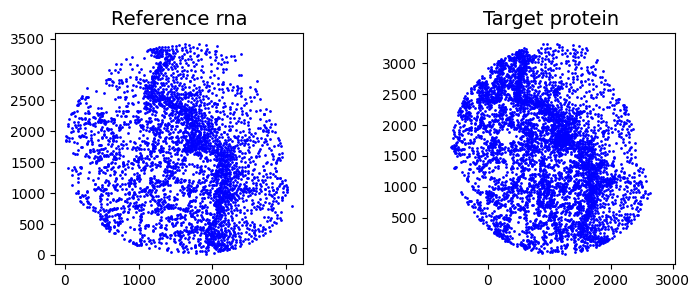

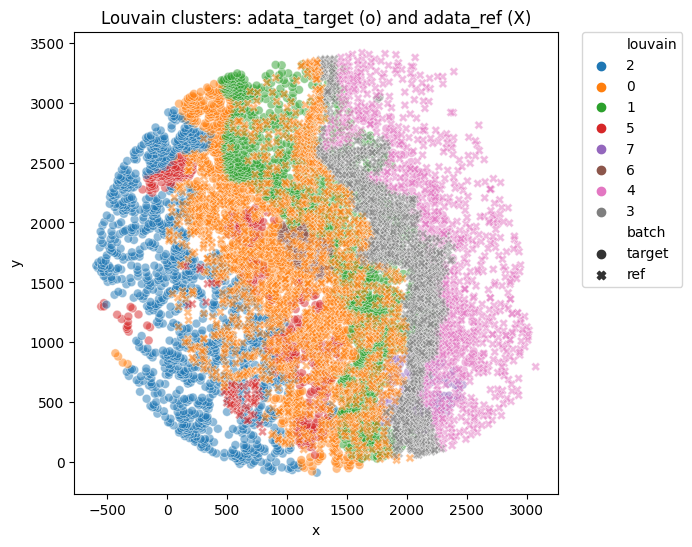

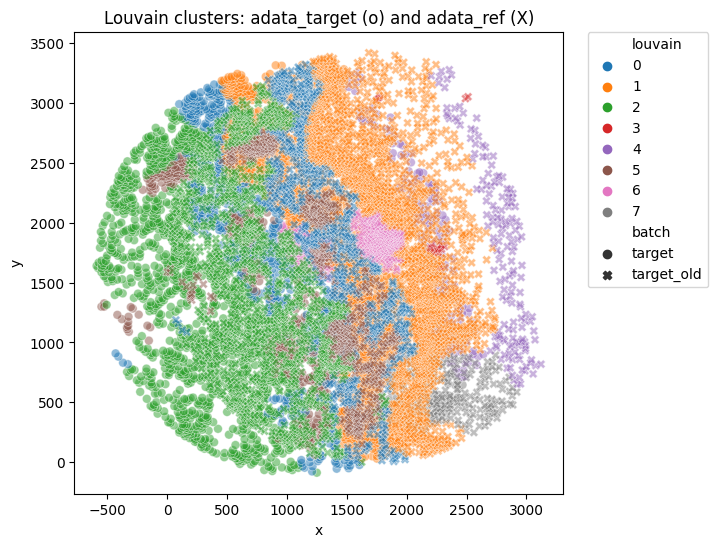

In [50]:
slice_target = 'protein'
slice_ref = 'rna'
landmark_domain = ['0','1','2','3','4','5','6','7']
aligned_coor = STAligner.ICP_align(adata_concat, adata_target, adata_ref, slice_target, slice_ref, landmark_domain, plot_align=True)
adata_target.obsm["X_spatial"] = aligned_coor


import seaborn as sns
import matplotlib.pyplot as plt

# Prepare data for both adata_target and adata_ref
df_target = adata_target.obs.copy()
df_target['x'] = adata_target.obsm['X_spatial'][:, 0]
df_target['y'] = adata_target.obsm['X_spatial'][:, 1]
df_target['batch'] = 'target'

df_ref = adata_ref.obs.copy()
df_ref['x'] = adata_ref.obsm['spatial'][:, 0]
df_ref['y'] = adata_ref.obsm['spatial'][:, 1]
df_ref['batch'] = 'ref'

# Concatenate dataframes
df_all = pd.concat([df_target, df_ref], axis=0)

# Plot both in the same plot, using marker style for batch and color for louvain
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_all,
    x='x', y='y',
    hue='louvain',
    style='batch',
    palette='tab10',
    s=40,
    alpha=0.5
)
plt.title('Louvain clusters: adata_target (o) and adata_ref (X)')
plt.gca().set_aspect('equal')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.show()




# Prepare data for both adata_target and adata_ref
df_target = adata_target.obs.copy()
df_target['x'] = adata_target.obsm['X_spatial'][:, 0]
df_target['y'] = adata_target.obsm['X_spatial'][:, 1]
df_target['batch'] = 'target'

df_ref = adata_target.obs.copy()
df_ref['x'] = adata_target.obs['New_X'].values
df_ref['y'] = adata_target.obs['New_Y'].values
df_ref['batch'] = 'target_old'

# Concatenate dataframes
df_all = pd.concat([df_target, df_ref], axis=0)

# Plot both in the same plot, using marker style for batch and color for louvain
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_all,
    x='x', y='y',
    hue='louvain',
    style='batch',
    palette='tab10',
    s=40,
    alpha=0.5
)
plt.title('Louvain clusters: adata_target (o) and adata_ref (X)')
plt.gca().set_aspect('equal')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.show()




In [51]:
adata_target.obsm['X_spatial']

array([[1248.96323457,  -88.41898731],
       [1514.99407414,  -50.98808426],
       [1209.60227972,  -77.98401003],
       ...,
       [1388.9201914 , 3241.95960322],
       [1475.04416908, 3282.72934152],
       [1391.23497812, 3296.24587671]])

In [52]:
adata_target.obs[['New_X','New_Y']]

,New_X,New_Y
32730,1624.137251,0.000000
32737,1892.723329,5.915993
32740,1586.274896,14.987182
32741,1792.940248,13.606784
32745,1884.835338,25.833169
...,...,...
51378,2042.397949,3275.488069
51379,2355.748373,3278.840465
51380,2154.407415,3290.869651
51381,2244.724906,3321.238415


In [53]:
#error due to edgeList
adata_target.uns['edgeList'] = []

In [54]:
adata_ref.uns['edgeList'] = []

In [55]:
adata_ref.obs

,transformed_x,transformed_y,in_ROI,New_X,New_Y,CellType,image_id,spatial_domain,spatial_domain_original,slice_name,cellID,Ground Truth,batch_name,louvain
3443715200455100055,10954.380002,13944.383429,True,3020.047524,1099.776842,Epithelial cells,ref,1,1,rna,3443715200455100055,Epithelial cells,rna,4
3443715200455100057,10946.573801,13890.089022,True,3012.241322,1045.482436,Epithelial cells,ref,1,1,rna,3443715200455100057,Epithelial cells,rna,4
3443715200455100058,10945.461033,13911.796937,True,3011.128555,1067.190351,Epithelial cells,ref,1,1,rna,3443715200455100058,Epithelial cells,rna,4
3443715200455100060,10943.683312,13863.000800,True,3009.350833,1018.394213,Epithelial cells,ref,1,1,rna,3443715200455100060,Epithelial cells,rna,4
3443715200456100090,11010.086369,13640.624477,True,3075.753890,796.017891,Epithelial cells,ref,1,1,rna,3443715200456100090,Epithelial cells,rna,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3443715201332100020,8029.336355,13972.897304,True,95.003876,1128.290717,Fibroblasts,ref,2,2,rna,3443715201332100020,Fibroblasts,rna,0
3443715201401100011,7972.166978,14969.823311,True,37.834499,2125.216724,Fibroblasts,ref,0,0,rna,3443715201401100011,Fibroblasts,rna,0
3443715201402100004,7956.907282,14757.080120,True,22.574803,1912.473533,Epithelial cells,ref,2,2,rna,3443715201402100004,Epithelial cells,rna,0
3443715201402100006,7953.306346,14773.880912,True,18.973867,1929.274325,Lymphoid cells,ref,2,2,rna,3443715201402100006,Lymphoid cells,rna,0


In [58]:
adata_target.obs.head()

,transformed_x,transformed_y,in_ROI,New_X,New_Y,CellType,image_id,spatial_domain,spatial_domain_original,slice_name,cellID,Ground Truth,batch_name,louvain
32730,9558.469730,12844.606586,True,1624.137251,0.000000,Myeloid cells,query,3,3,protein,6c8df374-8566-4a60-b133-eab85bba713d,Myeloid cells,protein,2
32737,9827.055808,12850.522579,True,1892.723329,5.915993,Fibroblasts,query,3,3,protein,a2b8665d-1a3b-41c0-b377-cc7f0bc63f8d,Fibroblasts,protein,0
32740,9520.607375,12859.593768,True,1586.274896,14.987182,Myeloid cells,query,0,0,protein,0f4d11bf-16da-4ee0-8bea-a526858d607e,Myeloid cells,protein,0
32741,9727.272727,12858.213370,True,1792.940248,13.606784,Myeloid cells,query,2,2,protein,8a6f6e48-4604-4dae-8e92-47f2ed17b539,Myeloid cells,protein,0
32745,9819.167817,12870.439755,True,1884.835338,25.833169,Fibroblasts,query,3,3,protein,e390053d-e183-4619-9404-8cd19b907c0d,Fibroblasts,protein,0


In [59]:
adata_target.obsm['X_spatial']

array([[1248.96323457,  -88.41898731],
       [1514.99407414,  -50.98808426],
       [1209.60227972,  -77.98401003],
       ...,
       [1388.9201914 , 3241.95960322],
       [1475.04416908, 3282.72934152],
       [1391.23497812, 3296.24587671]])

In [60]:
adata_target.obsm['X_STAligner_spatial'] = adata_target.obsm['X_spatial'].copy()
adata_target.write_h5ad('query_STAligner_Prot_tongue.h5ad')

In [63]:
adata_ref

AnnData object with n_obs × n_vars = 3608 × 16
    obs: 'transformed_x', 'transformed_y', 'in_ROI', 'New_X', 'New_Y', 'CellType', 'image_id', 'spatial_domain', 'spatial_domain_original', 'slice_name', 'cellID', 'Ground Truth', 'batch_name', 'louvain'
    uns: 'edgeList', 'neighbors', 'louvain', 'umap'
    obsm: 'X_spatial', 'spatial', 'STAGATE', 'STAligner', 'X_umap', 'X_STAligner_spatial'
    obsp: 'distances', 'connectivities'

In [62]:
adata_ref.obsm['X_STAligner_spatial'] = adata_ref.obsm['X_spatial'].copy()
adata_ref.write_h5ad('ref_STAligner_RNA_tongue.h5ad')



In [29]:
# Compute nearest neighbor cell type match between adata_ref and adata_target

# Get coordinates from adata_ref and adata_target
ref_coords = adata_ref.obsm['spatial']
query_coords = adata_target.obsm['X_spatial']

# Get cell types (assuming 'CellType' exists in .obs)
ref_celltypes = adata_ref.obs['Ground Truth'].values
query_celltypes = adata_target.obs['Ground Truth'].values

# Find nearest reference cell for each query cell
from scipy.spatial import cKDTree
tree = cKDTree(ref_coords)
dists, idxs = tree.query(query_coords, k=1)

# Compare cell types
matches = query_celltypes == ref_celltypes[idxs]

# Print summary
print(f"Number of matches: {matches.sum()} / {len(matches)}")
print(f"Match percentage: {matches.mean()*100:.2f}%")

# Annotate adata_target with nearest ref cell type and match status
adata_target.obs['NearestRefCellType'] = ref_celltypes[idxs]
adata_target.obs['CellTypeMatch'] = matches


Number of matches: 1967 / 3608
Match percentage: 54.52%


In [30]:
# Compute nearest neighbor cell type match between adata_ref and adata_target

# Get coordinates from adata_ref and adata_target
ref_coords = adata_ref.obsm['spatial']
query_coords = adata_target.obs[['New_X','New_Y']].values

# Get cell types (assuming 'CellType' exists in .obs)
ref_celltypes = adata_ref.obs['Ground Truth'].values
query_celltypes = adata_target.obs['Ground Truth'].values

# Find nearest reference cell for each query cell
from scipy.spatial import cKDTree
tree = cKDTree(ref_coords)
dists, idxs = tree.query(query_coords, k=1)

# Compare cell types
matches = query_celltypes == ref_celltypes[idxs]

# Print summary
print(f"Number of matches: {matches.sum()} / {len(matches)}")
print(f"Match percentage: {matches.mean()*100:.2f}%")

# Annotate adata_target with nearest ref cell type and match status
adata_target.obs['NearestRefCellType'] = ref_celltypes[idxs]
adata_target.obs['CellTypeMatch'] = matches


Number of matches: 2292 / 3608
Match percentage: 63.53%


In [34]:
adata_ref.X

<3801x67 sparse matrix of type '<class 'numpy.float32'>'
	with 104002 stored elements in Compressed Sparse Row format>

In [36]:
adata_ref.obs['CellType'] = adata_ref.obs['Ground Truth'].astype('category')
adata_ref.X = adata_ref.X.toarray()
adata_ref.write_h5ad('ref_STAligner.h5ad')

adata_target.obs['CellType'] = adata_target.obs['Ground Truth'].astype('category')
adata_target.X = adata_target.X.toarray()
adata_target.write_h5ad('query_STAligner.h5ad')






AttributeError: 'numpy.ndarray' object has no attribute 'toarray'